# HDB Rental Main Dataset

### Import dependencies

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder

data_dir = "../data"

## Section 1: Preprocessing

In this section, we explore preprocessing steps alongside justification for each. These steps are applied to the train set first, followed by the test set afterwards. The output of this section are both their cleaned `.csv` files.

In [2]:
original_df = pd.read_csv(f"{data_dir}/train.csv")
df = original_df.copy()
df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800
...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.0,yes,1985,0.0,2500
149996,2025-03,queenstown,79,dawson road,5-room,improved,107.0,yes,2020,0.0,5300
149997,2025-03,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.0,yes,1971,0.0,2650
149998,2025-03,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.0,yes,2001,0.0,3300


### 1.1 MONTH_INDEX

The attribute `RENT_APPROVAL_DATE` is in a datetime format, which is not easily parsable by some models. We will replace this with `MONTH_INDEX`, which is simply the monthly index starting from the first observation month (e.g. `2021-01` = `0`, `2021-02` = `1`).

In [ ]:
date = pd.to_datetime(df['RENT_APPROVAL_DATE'], format="%Y-%m")
df.insert(loc=1, column='MONTH_INDEX', value=(date.dt.year - 2021) * 12 + date.dt.month - 1)
df

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,0,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800
1,2021-01,0,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000
2,2021-01,0,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000
3,2021-01,0,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400
4,2021-01,0,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800
...,...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,50,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.0,yes,1985,0.0,2500
149996,2025-03,50,queenstown,79,dawson road,5-room,improved,107.0,yes,2020,0.0,5300
149997,2025-03,50,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.0,yes,1971,0.0,2650
149998,2025-03,50,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.0,yes,2001,0.0,3300


### 1.2 Duplicates and Missing Values
Let us check for any exact duplicates and missing values.

In [4]:
df.duplicated().sum()

425

There are 425 exact duplicate records in the dataset—this may sound alarming, but these duplicates may also reflect real records. The dataset only covers HDB flats down to the block level, so it is entirely possible that different units of the same flat type were rented at the same block within the same month. Furthermore, this affects only a very small portion of the dataset (~2.83%), so our verdict is to keep these duplicates.

In [5]:
df.isna().any(axis=1).sum()

0

There are no missing values which is good.

### 1.3 Dropping FURNISHED and FEE

In [6]:
df['FURNISHED'].value_counts()

FURNISHED
yes    150000
Name: count, dtype: int64

In [7]:
df['FEE'].value_counts()

FEE
0.0    150000
Name: count, dtype: int64

From the code cells above, we may note that the attributes `FURNISHED` and `FEE` all have constant values. This does not provide us with any insights, so we will drop these attributes.

In [8]:
df.drop(columns=['FURNISHED', 'FEE'], inplace=True)
df

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,MONTHLY_RENT
0,2021-01,0,punggol,604a,punggol road,4 room,model a,93.0,2012,1800
1,2021-01,0,sengkang,290c,compassvale crescent,5 room,improved,110.0,2001,2000
2,2021-01,0,queenstown,5,ghim moh road,3 room,improved,65.0,1976,2000
3,2021-01,0,sengkang,436b,fernvale road,4 room,model a,96.0,2010,1400
4,2021-01,0,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,2001,1800
...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,50,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.0,1985,2500
149996,2025-03,50,queenstown,79,dawson road,5-room,improved,107.0,2020,5300
149997,2025-03,50,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.0,1971,2650
149998,2025-03,50,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.0,2001,3300


### 1.4 Normalizing STREET

Set `STREET` names all to lowercase for consistency

In [9]:
# Normalize to lowercase
df['STREET'] = df['STREET'].str.lower()

In [10]:
df['STREET'].value_counts()

STREET
ang mo kio avenue 3      2014
ang mo kio avenue 10     1889
yishun ring road         1888
bedok reservoir road     1508
lorong 1 toa payoh       1229
                         ... 
margaret drive              3
yishun street 44            2
ang mo kio street 23        2
yishun street 42            2
bukit batok street 41       2
Name: count, Length: 576, dtype: int64

### 1.5 Adding FLAT_AGE

`RENT_APPROVAL_DATE` and `LEASE_COMMENCE_DATE` are not very useful for regression, so we will engineer a new `FLAT_AGE` feature which is simply their difference in years.

In [ ]:
df['RENT_APPROVAL_YEAR'] = df['RENT_APPROVAL_DATE'].str[:4].astype(int)
df.insert(loc=8, column='FLAT_AGE', value=df['RENT_APPROVAL_YEAR'] - df['LEASE_COMMENCE_DATE'])

df.drop(columns=['RENT_APPROVAL_YEAR', 'LEASE_COMMENCE_DATE'], inplace=True)
df

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
0,2021-01,0,punggol,604a,punggol road,4 room,model a,93.0,9,1800
1,2021-01,0,sengkang,290c,compassvale crescent,5 room,improved,110.0,20,2000
2,2021-01,0,queenstown,5,ghim moh road,3 room,improved,65.0,45,2000
3,2021-01,0,sengkang,436b,fernvale road,4 room,model a,96.0,11,1400
4,2021-01,0,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,20,1800
...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,50,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.0,40,2500
149996,2025-03,50,queenstown,79,dawson road,5-room,improved,107.0,5,5300
149997,2025-03,50,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.0,54,2650
149998,2025-03,50,sembawang,360a,admiralty drive,4-room,premium apartment,94.0,24,3300


### 1.6 Integer Encoding FLAT_TYPE

Standardize inconsistent hyphenation of the values (i.e., `4 room` to `4-room`). Then, to make the features better suited for regression, we perform integer encoding (i.e., `executive` = `6`, `5-room` = `5`, etc.).

In [ ]:
df['FLAT_TYPE'].value_counts()

FLAT_TYPE
4-room       40688
3-room       36932
5-room       26215
4 room       13391
3 room       12092
5 room        9308
executive     8234
2-room        2566
2 room         532
1-room          34
1 room           8
Name: count, dtype: int64

In [ ]:
# Standardize hyphenation
df['FLAT_TYPE'] = df['FLAT_TYPE'].str.replace(" room", "-room")

In [14]:
# Integer encoding
flat_type_encoding = {
    "executive": 6,
    "5-room": 5,
    "4-room": 4,
    "3-room": 3,
    "2-room": 2,
    "1-room": 1
}

df["FLAT_TYPE"] = df["FLAT_TYPE"].map(flat_type_encoding)

In [ ]:
df['FLAT_TYPE'].value_counts()

FLAT_TYPE
4    54079
3    49024
5    35523
6     8234
2     3098
1       42
Name: count, dtype: int64

### 1.7 FLAT_TYPE vs. FLOOR_AREA_SQM

Based on the correlation matrix below, `FLAT_TYPE` and `FLOOR_AREA_SQM` have 0.95 correlation with each other which is very high, and they correlate with `MONTHLY_RENT` by 0.34 and 0.33, respectively. We could probably drop one of them since keeping both is redundant. To determine which to drop, we fit multiple models with varying configurations of the features.

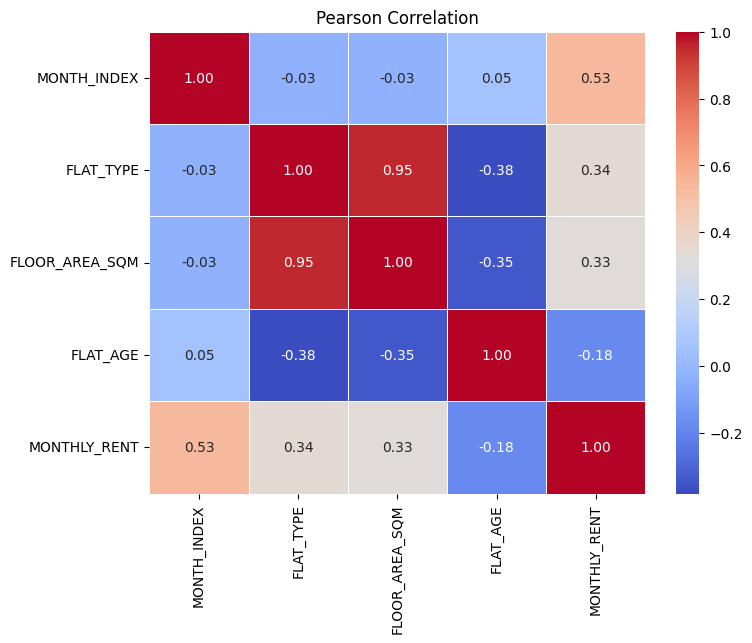

In [16]:
matrix = df[['MONTH_INDEX', 'FLAT_TYPE', 'FLOOR_AREA_SQM', 'FLAT_AGE', 'MONTHLY_RENT']].corr()
plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Pearson Correlation")
plt.show()

For testing, let us fit three simple linear regression models: (1) with `FLAT_TYPE`, (2) with `FLOOR_AREA_AQM`, and (3) with both features. Among the three configurations, the model with both `FLAT_TYPE` and `FLOOR_AREA_SQM` performs the best (lowest MAE and highest R^2). Therefore, we will keep both `FLAT_TYPE` and `FLOOR_AREA_SQM`.

In [17]:
# Helper function: Train-test split by time
def time_split(df, features, train_percent):
    data = df.copy()
    data = data[features + ["MONTHLY_RENT", "RENT_APPROVAL_DATE"]]
    data["RENT_APPROVAL_DATE"] = pd.to_datetime(data["RENT_APPROVAL_DATE"], format="%Y-%m")
    data = data.sort_values("RENT_APPROVAL_DATE")

    # Example: First 80% for training, last 20% for testing (chronological)
    cutoff_date = data["RENT_APPROVAL_DATE"].iloc[int(len(data) * train_percent)]
    train = data[data["RENT_APPROVAL_DATE"] < cutoff_date]
    test = data[data["RENT_APPROVAL_DATE"] >= cutoff_date]

    return train, test, cutoff_date

In [18]:
ablation_features = [
    ["FLAT_TYPE"],                      # FLAT_TYPE
    ["FLOOR_AREA_SQM"],                 # FLOOR_AREA_SQM
    ["FLAT_TYPE", "FLOOR_AREA_SQM"]     # both
]

features = ["MONTH_INDEX", "FLAT_TYPE", "FLOOR_AREA_SQM", "FLAT_AGE"]
train_df, test_df, cutoff_date = time_split(df, features, 0.8)

for ablation in ablation_features:
    selected_features = ["MONTH_INDEX", "FLAT_AGE"] + ablation
    
    X_train = train_df[selected_features]
    X_test = test_df[selected_features]
    y_train = train_df["MONTHLY_RENT"]
    y_test = test_df["MONTHLY_RENT"]

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("Features:", selected_features)
    print("Cutoff:", cutoff_date)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R^2:", r2_score(y_test, predictions))
    print()

Features: ['MONTH_INDEX', 'FLAT_AGE', 'FLAT_TYPE']
Cutoff: 2024-05-01 00:00:00
MAE: 523.4740147213819
RMSE: 675.728707611588
R^2: -0.057850539794119804

Features: ['MONTH_INDEX', 'FLAT_AGE', 'FLOOR_AREA_SQM']
Cutoff: 2024-05-01 00:00:00
MAE: 526.785213394172
RMSE: 679.9060522089295
R^2: -0.07097019950950867

Features: ['MONTH_INDEX', 'FLAT_AGE', 'FLAT_TYPE', 'FLOOR_AREA_SQM']
Cutoff: 2024-05-01 00:00:00
MAE: 523.3148036394598
RMSE: 675.5838044566138
R^2: -0.057396897840829686



### 1.8 FLAT_MODEL Suspicious Values

All flat models look valid, except for a suspicious `2 room` model which seems redundant since this is identical to the `FLAT_TYPE`.

In [19]:
df["FLAT_MODEL"].value_counts()

FLAT_MODEL
improved                  44008
model a                   42745
new generation            27380
premium apartment         12312
simplified                 6794
standard                   5903
apartment                  4724
maisonette                 2346
model a2                   1553
dbss                       1090
type s1                     299
2 room                      224
adjoined flat               218
type s2                     160
model a maisonette          140
premium apartment loft       51
premium maisonette           21
terrace                      19
3gen                         12
improved maisonette           1
Name: count, dtype: int64

As expected, all `FLAT_MODEL = 2 room` records are of `FLAT_TYPE = 2`.

In [20]:
df[df["FLAT_MODEL"] == "2 room"]

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
65,2021-01,0,central,9,jalan kukoh,2,2 room,55.0,39,1500
1320,2021-01,0,bukit merah,127a,kim tian road,2,2 room,47.0,8,1800
2282,2021-01,0,pasir ris,528a,pasir ris street 51,2,2 room,47.0,6,1700
6577,2021-03,2,punggol,256a,sumang walk,2,2 room,47.0,5,1600
7372,2021-03,2,hougang,993a,buangkok link,2,2 room,47.0,0,1700
...,...,...,...,...,...,...,...,...,...,...
149721,2025-03,50,bukit merah,127a,kim tian road,2,2 room,47.0,12,3000
149737,2025-03,50,hougang,994b,buangkok link,2,2 room,47.0,4,2500
149770,2025-03,50,yishun,462a,yishun avenue 6,2,2 room,38.0,6,2400
149773,2025-03,50,bukit batok,436a,bukit batok west avenue 5,2,2 room,47.0,5,2500


Comparing it with other records with `FLAT_TYPE = 2`, we may note that the `FLAT_MODEL` values can be more varied and descriptive.

In [21]:
df[df["FLAT_TYPE"] == 2]

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
16,2021-01,0,geylang,32,balam road,2,standard,46.0,48,1600
52,2021-01,0,toa payoh,54,lorong 5 toa payoh,2,standard,43.0,54,1000
65,2021-01,0,central,9,jalan kukoh,2,2 room,55.0,39,1500
141,2021-01,0,woodlands,780f,woodlands crescent,2,model a,47.0,6,1000
174,2021-01,0,bedok,541,bedok north street 3,2,improved,45.0,36,1500
...,...,...,...,...,...,...,...,...,...,...
149743,2025-03,50,bukit merah,48,lower delta road,2,standard,42.0,55,2200
149770,2025-03,50,yishun,462a,yishun avenue 6,2,2 room,38.0,6,2400
149773,2025-03,50,bukit batok,436a,bukit batok west avenue 5,2,2 room,47.0,5,2500
149789,2025-03,50,jurong west,150a,corporation drive,2,2 room,47.0,6,2150


If we consider `2 room` values for `FLAT_MODEL` as an error, we can attempt a reconstruction. One approach is to determine the `FLAT_MODEL` of other records at similar `BLOCK`, `STREET` and `FLAT_TYPE` combinations. However, the issue with this approach is that records with `2 room` values appear to have all their records completely affected for their `BLOCK`, `STREET`, and `FLAT_TYPE` combinations. See below as an example.

In [22]:
df[(df['BLOCK'] == "9") & (df['STREET'] == "jalan kukoh") & (df['FLAT_TYPE'] == 2)].head(10)

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
65,2021-01,0,central,9,jalan kukoh,2,2 room,55.0,39,1500
24357,2021-08,7,central,9,jalan kukoh,2,2 room,55.0,39,1550
29417,2021-10,9,central,9,jalan kukoh,2,2 room,55.0,39,1650
31912,2021-11,10,central,9,jalan kukoh,2,2 room,55.0,39,1900
35377,2021-12,11,central,9,jalan kukoh,2,2 room,55.0,39,1200
36185,2021-12,11,central,9,jalan kukoh,2,2 room,55.0,39,1400
45578,2022-03,14,central,9,jalan kukoh,2,2 room,55.0,40,1500
56377,2022-07,18,central,9,jalan kukoh,2,2 room,55.0,40,2400
57648,2022-07,18,central,9,jalan kukoh,2,2 room,55.0,40,2000
65040,2022-11,22,central,9,jalan kukoh,2,2 room,55.0,40,1200


Consequently, there does not seem to be a reliable way to fix or reconstruct the real value for `FLAT_MODEL`. It does not seem to be worth dropping the records either just because of this minor issue, so the verdict is to leave the `2 room` records as is.

### 1.9 STREET vs BLOCK_STREET

The `BLOCK` feature is quite useless without the `STREET`. We can either drop `BLOCK`, or combine both `BLOCK` and `STREET` into a single feature. We create a new feature for this called `BLOCK_STREET`.

In [23]:
df.insert(loc=2, column='BLOCK_STREET', value=df["BLOCK"] + " " + df["STREET"])

# df.drop(columns=["BLOCK", "STREET"], inplace=True)
df

,RENT_APPROVAL_DATE,MONTH_INDEX,BLOCK_STREET,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
0,2021-01,0,604a punggol road,punggol,604a,punggol road,4,model a,93.0,9,1800
1,2021-01,0,290c compassvale crescent,sengkang,290c,compassvale crescent,5,improved,110.0,20,2000
2,2021-01,0,5 ghim moh road,queenstown,5,ghim moh road,3,improved,65.0,45,2000
3,2021-01,0,436b fernvale road,sengkang,436b,fernvale road,4,model a,96.0,11,1400
4,2021-01,0,467b admiralty drive,sembawang,467b,admiralty drive,4,premium apartment,102.0,20,1800
...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,50,220 bukit batok east avenue 3,bukit batok,220,bukit batok east avenue 3,3,new generation,67.0,40,2500
149996,2025-03,50,79 dawson road,queenstown,79,dawson road,5,improved,107.0,5,5300
149997,2025-03,50,17 lorong 7 toa payoh,toa payoh,17,lorong 7 toa payoh,3,improved,67.0,54,2650
149998,2025-03,50,360a admiralty drive,sembawang,360a,admiralty drive,4,premium apartment,94.0,24,3300


In [24]:
df['STREET'].value_counts()

STREET
ang mo kio avenue 3      2014
ang mo kio avenue 10     1889
yishun ring road         1888
bedok reservoir road     1508
lorong 1 toa payoh       1229
                         ... 
margaret drive              3
yishun street 44            2
ang mo kio street 23        2
yishun street 42            2
bukit batok street 41       2
Name: count, Length: 576, dtype: int64

In [25]:
df['BLOCK_STREET'].value_counts()

BLOCK_STREET
4 holland close              136
8 holland avenue             131
11 holland drive             127
13 holland drive             125
2 holland avenue             124
                            ... 
314 bukit batok street 32      1
666a punggol drive             1
342 woodlands avenue 1         1
116 marsiling rise             1
604b tampines avenue 9         1
Name: count, Length: 9406, dtype: int64

In [26]:
ablation_features = [
    ['BLOCK_STREET'],               # BLOCK_STREET
    ['STREET'],                     # STREET
]

features = ['MONTH_INDEX', 'FLAT_TYPE', 'FLAT_AGE', 'STREET', 'BLOCK_STREET']
train_df, test_df, cutoff_date = time_split(df, features, 0.8)

for ablation in ablation_features:
    selected_features = ['MONTH_INDEX', 'FLAT_TYPE', 'FLAT_AGE'] + ablation

    X_train = train_df[selected_features]
    X_test = test_df[selected_features]
    y_train = train_df['MONTHLY_RENT']
    y_test = test_df['MONTHLY_RENT']

    encoder = OneHotEncoder(handle_unknown='ignore')

    train_street_df = encoder.fit_transform(X_train[ablation])
    test_street_df = encoder.transform(X_test[ablation])
    street_columns = encoder.get_feature_names_out(ablation)

    train_street_df = pd.DataFrame.sparse.from_spmatrix(train_street_df, columns=street_columns, index=X_train.index)
    test_street_df = pd.DataFrame.sparse.from_spmatrix(test_street_df, columns=street_columns, index=X_test.index)

    train_other_df = X_train.drop(columns=ablation).astype(pd.SparseDtype("float64", 0))
    test_other_df = X_test.drop(columns=ablation).astype(pd.SparseDtype("float64", 0))

    X_train_final = pd.concat([train_other_df, train_street_df], axis=1)
    X_test_final = pd.concat([test_other_df, test_street_df], axis=1)

    model = LinearRegression()
    model.fit(X_train_final.sparse.to_coo().tocsr(), y_train)
    predictions = model.predict(X_test_final.sparse.to_coo().tocsr())

    print("Features:", selected_features)
    print("Cutoff:", cutoff_date)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R^2:", r2_score(y_test, predictions))
    print()

Features: ['MONTH_INDEX', 'FLAT_TYPE', 'FLAT_AGE', 'BLOCK_STREET']
Cutoff: 2024-05-01 00:00:00
MAE: 460.40240216405545
RMSE: 608.8649232979153
R^2: 0.14114176839318426

Features: ['MONTH_INDEX', 'FLAT_TYPE', 'FLAT_AGE', 'STREET']
Cutoff: 2024-05-01 00:00:00
MAE: 456.5392129356981
RMSE: 612.5849533163323
R^2: 0.13061484005089274



The cardinality of `BLOCK_STREET` seems a bit too high (576 -> 9406), so it probably would not be a good idea using `BLOCK_STREET`.  Consequently, let us use `STREET` only and drop `BLOCK` entirely.

In [27]:
X_train_final

,MONTH_INDEX,FLAT_TYPE,FLAT_AGE,STREET_admiralty drive,STREET_admiralty link,STREET_ah hood road,STREET_aljunied avenue 2,STREET_aljunied crescent,STREET_aljunied road,STREET_alkaff crescent,...,STREET_yishun street 72,STREET_yishun street 81,STREET_yuan ching road,STREET_yung an road,STREET_yung ho road,STREET_yung kuang road,STREET_yung loh road,STREET_yung ping road,STREET_yung sheng road,STREET_zion road
0,0,4.0,9.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2080,0,3.0,41.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2081,0,3.0,54.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2082,0,3.0,46.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2083,0,5.0,32.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115889,39.0,4.0,23.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
115894,39.0,3.0,43.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
115885,39.0,4.0,10.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
115887,39.0,3.0,42.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [28]:
# One-hot encode STREET
# df = pd.get_dummies(df, columns=['STREET'], dtype="uint8")

In [29]:
# df.drop(columns=['BLOCK'], inplace=True)
df.drop(columns=['BLOCK_STREET'], inplace=True)
df.drop(columns=['RENT_APPROVAL_DATE'], inplace=True)

### Section 1 Summary
- Add `MONTH_INDEX`, and `FLAT_AGE`
- Drop `FURNISHED`, `FEE`, `LEASE_COMMENCE_DATE`, and `BLOCK`
- Normalize `STREET`
- Integer encode `FLAT_TYPE`
- One-hot encode `STREET`
- Use `RENT_APPROVAL_DATE` for train-test split by time; otherwise, it is not really needed
- Keep `FLOOR_AREA_SQM` for now and test its inclusion in the final model; drop it if performance does not improve

Let us inspect the main dataset before and after preprocessing.

Before:

In [30]:
original_df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800
...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.0,yes,1985,0.0,2500
149996,2025-03,queenstown,79,dawson road,5-room,improved,107.0,yes,2020,0.0,5300
149997,2025-03,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.0,yes,1971,0.0,2650
149998,2025-03,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.0,yes,2001,0.0,3300


After:

In [31]:
df

,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
0,0,punggol,604a,punggol road,4,model a,93.0,9,1800
1,0,sengkang,290c,compassvale crescent,5,improved,110.0,20,2000
2,0,queenstown,5,ghim moh road,3,improved,65.0,45,2000
3,0,sengkang,436b,fernvale road,4,model a,96.0,11,1400
4,0,sembawang,467b,admiralty drive,4,premium apartment,102.0,20,1800
...,...,...,...,...,...,...,...,...,...
149995,50,bukit batok,220,bukit batok east avenue 3,3,new generation,67.0,40,2500
149996,50,queenstown,79,dawson road,5,improved,107.0,5,5300
149997,50,toa payoh,17,lorong 7 toa payoh,3,improved,67.0,54,2650
149998,50,sembawang,360a,admiralty drive,4,premium apartment,94.0,24,3300


In [32]:
# Output cleaned CSV
df.to_csv('../cleaned/train_cleaned.csv', index=False)

### Test Set: Preprocessing

We repeat the same preprocessing steps done on the train set to the test set as well. Then, we output the cleaned `.csv`.

In [53]:
test_df = pd.read_csv(f"{data_dir}/test.csv")
df = test_df.copy()

Replace `RENT_APPROVAL_DATE` with `MONTH_INDEX`.

In [54]:
date = pd.to_datetime(df['RENT_APPROVAL_DATE'], format="%Y-%m")
df.insert(loc=1, column='MONTH_INDEX', value=(date.dt.year - 2021) * 12 + date.dt.month - 1)

Drop constant columns `FURNISHED` and `FEE`.

In [55]:
df.drop(columns=['FURNISHED', 'FEE'], inplace=True)

Set `STREET` names all to lowercase.

In [56]:
# Normalize to lowercase
df['STREET'] = df['STREET'].str.lower()

Derive `FLAT_AGE` from `RENT_APPROVAL_DATE` and `LEASE_COMMENCE_DATE`.

In [57]:
df['RENT_APPROVAL_YEAR'] = df['RENT_APPROVAL_DATE'].str[:4].astype(int)
df.insert(loc=8, column='FLAT_AGE', value=df['RENT_APPROVAL_YEAR'] - df['LEASE_COMMENCE_DATE'])

df.drop(columns=['RENT_APPROVAL_YEAR', 'LEASE_COMMENCE_DATE'], inplace=True)

Standardize inconsistent `FLAT_TYPE` values, then encode the categorical values into integers.

In [58]:
# Standardize hyphenation
df['FLAT_TYPE'] = df['FLAT_TYPE'].str.replace(" room", "-room")

In [59]:
# Integer encoding
flat_type_encoding = {
    "executive": 6,
    "5-room": 5,
    "4-room": 4,
    "3-room": 3,
    "2-room": 2,
    "1-room": 1
}

df['FLAT_TYPE'] = df['FLAT_TYPE'].map(flat_type_encoding)

Drop unnecessary attributes.

In [ ]:
# df.drop(columns=['BLOCK'], inplace=True)
df.drop(columns=['RENT_APPROVAL_DATE'], inplace=True)

Let us inspect the test dataset before and after preprocessing.

Before:

In [61]:
test_df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE
0,2025-03,kallang/whampoa,74,Whampoa Drive,3-room,improved,66.0,yes,1981,0.0
1,2025-03,bukit timah,6,farrer road,4-room,improved,91.0,yes,1974,0.0
2,2025-03,pasir ris,755,Pasir Ris Street 71,4-room,model a,105.0,yes,1996,0.0
3,2025-03,punggol,299,punggol central,4-room,premium apartment,94.0,yes,2003,0.0
4,2025-03,tampines,869a,tampines avenue 8,4-room,model a,92.0,yes,2015,0.0
...,...,...,...,...,...,...,...,...,...,...
49995,2026-07,bukit batok,138,bukit batok west avenue 6,3-room,new generation,68.0,yes,1984,0.0
49996,2026-07,queenstown,88,dawson road,4-room,premium apartment,83.0,yes,2016,0.0
49997,2026-07,toa payoh,235,lorong 8 toa payoh,3-room,improved,76.0,yes,1976,0.0
49998,2026-07,bukit panjang,613,Bukit Panjang Ring Road,4-room,model a,90.0,yes,2002,0.0


After:

In [62]:
df

,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE
0,50,kallang/whampoa,74,whampoa drive,3,improved,66.0,44
1,50,bukit timah,6,farrer road,4,improved,91.0,51
2,50,pasir ris,755,pasir ris street 71,4,model a,105.0,29
3,50,punggol,299,punggol central,4,premium apartment,94.0,22
4,50,tampines,869a,tampines avenue 8,4,model a,92.0,10
...,...,...,...,...,...,...,...,...
49995,66,bukit batok,138,bukit batok west avenue 6,3,new generation,68.0,42
49996,66,queenstown,88,dawson road,4,premium apartment,83.0,10
49997,66,toa payoh,235,lorong 8 toa payoh,3,improved,76.0,50
49998,66,bukit panjang,613,bukit panjang ring road,4,model a,90.0,24


In [63]:
# Output cleaned CSV
df.to_csv('../cleaned/test_cleaned.csv', index=False)